# Assignment 2

In [1]:
# imports section
# pip install numpy matplotlib requests nltk textblob gensim

import json
import os
import re
import string

import numpy as np
import matplotlib.pyplot as plt
import requests
import nltk
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from textblob import Word

for resource in ['wordnet', 'omw-1.4', 'stopwords', 'punkt', 'punkt_tab',
                 'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng']:
    nltk.download(resource, quiet=True)

IMAGES_DIR = 'images/assignment-2'
os.makedirs(IMAGES_DIR, exist_ok=True)

## Extract data from the json file

Write a script, that would extract all the the data from the json file and return it in a list of texts for further use in the next tasks

In [2]:
def extract_texts_from_file(file_path):
    """
    Extract the text data from the json file

    Args:
        file_path (str): Relative location of the json file in the project.

    Returns:
        list: The list of texts as strings.
    """
    with open(file_path, encoding='utf-8') as f:
        data = json.load(f)

    # collect every string in the json, whatever its structure is
    texts = []
    def collect(node):
        if isinstance(node, str):
            texts.append(node)
        elif isinstance(node, dict):
            for value in node.values():
                collect(value)
        elif isinstance(node, list):
            for value in node:
                collect(value)
    collect(data)
    return texts

texts = extract_texts_from_file('resources/data.json')
print(texts)

['Oppenheimer, directed by Christopher Nolan, delves into the life of J. Robert Oppenheimer, the theoretical physicist who led the development of the atomic bomb. The film explores his moral and emotional struggles.', "Oppenheimer captures the life of the 'father of the atomic bomb' and his internal conflict after the success of the Manhattan Project. The film's complex narrative reflects on the cost of scientific achievement.", 'In Oppenheimer, Cillian Murphy delivers a riveting performance as the conflicted physicist who grapples with the consequences of his groundbreaking work on the atomic bomb, under the weight of global politics and ethics.', 'Oppenheimer is a cinematic exploration of ambition, guilt, and responsibility. Through stunning visuals and a thought-provoking story, Nolan brings the life of the brilliant but haunted physicist to the big screen.', 'Ducks are versatile waterfowl, known for their adaptability in freshwater and coastal habitats. With webbed feet and waterpr

## Process the texts

Write a script, that would process these texts. Processing should include:

- Lowercasing
- Removing Punctuation
- Removing Special Characters and Numbers
- Stemming or Lemmatization
- Handling Abbreviations
- Spelling Correction

In [3]:
ABBREVIATIONS = {
    "it's": 'it is', "it’s": 'it is', "don't": 'do not', "doesn't": 'does not', "can't": 'cannot',
    "won't": 'will not', "isn't": 'is not', "aren't": 'are not', "i'm": 'i am', "they're": 'they are',
    "we're": 'we are', "you're": 'you are', "i've": 'i have', "let's": 'let us',
    'e.g.': 'for example', 'i.e.': 'that is', 'etc.': 'et cetera', 'vs.': 'versus',
    'dr.': 'doctor', 'mr.': 'mister', 'mrs.': 'missis', 'u.s.': 'united states', 'usa': 'united states',
    'uk': 'united kingdom', 'ai': 'artificial intelligence', 'ml': 'machine learning',
    'nlp': 'natural language processing', 'gdp': 'gross domestic product', 'covid': 'coronavirus disease',
}

STOP_WORDS = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def _wordnet_pos(tag):
    return {'J': wordnet.ADJ, 'V': wordnet.VERB, 'R': wordnet.ADV}.get(tag[0], wordnet.NOUN)

def _correct_spelling(word, proper_nouns):
    # names and words already known to wordnet must not be "corrected"
    if word in proper_nouns or len(word) < 4 or wordnet.synsets(word):
        return word
    suggestion, confidence = Word(word).spellcheck()[0]
    return suggestion if confidence > 0.8 else word

def process_text(text):
    # proper nouns (capitalized words not at sentence start) are kept from spelling correction
    proper_nouns = {w.lower() for w in re.findall(r'(?<![.!?]\s)(?<!^)\b[A-Z][a-z]+', text)}

    text = text.lower()
    # abbreviations must be expanded before the punctuation is removed
    for abbr, full in ABBREVIATIONS.items():
        text = re.sub(r'(?<!\w)' + re.escape(abbr) + r'(?!\w)', full, text)
    text = text.replace("'s", '').replace('’s', '')
    text = text.translate(str.maketrans({c: ' ' for c in string.punctuation + '’‘“”–—'}))
    text = re.sub(r'[^a-z\s]', ' ', text)          # special characters and numbers

    tokens = [t for t in text.split() if t not in STOP_WORDS and len(t) > 1]
    tokens = [_correct_spelling(t, proper_nouns) for t in tokens]
    tokens = [lemmatizer.lemmatize(t, _wordnet_pos(tag)) for t, tag in nltk.pos_tag(tokens)]
    return ' '.join(tokens)

def process_texts(texts):
    """
    Process the texts

    Args:
        texts (list): list of str texts to be processed.

    Returns:
        list: The list of texts as strings processed by script.
    """
    return [process_text(t) for t in texts]

texts_processed = process_texts(texts)
print(texts_processed)

['oppenheimer direct christopher nolan delve life robert oppenheimer theoretical physicist lead development atomic bomb film explore moral emotional struggle', 'oppenheimer capture life father atomic bomb internal conflict success manhattan project film complex narrative reflect cost scientific achievement', 'oppenheimer cillian murphy delivers rivet performance conflict physicist grapple consequence groundbreaking work atomic bomb weight global politics ethic', 'oppenheimer cinematic exploration ambition guilt responsibility stun visual thought provoke story nolan bring life brilliant haunt physicist big screen', 'duck versatile waterfowl know adaptability freshwater coastal habitat web foot waterproof feather excellent swimmer migrate long distance find food warmer climate', 'lamp spider talk yesterday fly nobody noticed except toaster watch blue smell well today door laugh understand whisper secret orange sock', 'duck communicate use range vocalization include quack whistle grunt so

## Calculate cosine similarities using TFIDF

Calculate the TFIDF score and cosine similarity between the texts. You may use gensim, write your own script using numpy or use other module. Output the result as a matrix $n\times n$  of cosine similarity scores (where $n$ is the length of texts list).

Extra credit: use word2vec word embeddings in vector spaces to get better TFIDF scores by representing each word as a vector.

In [4]:
from collections import Counter

def tfidf_matrix(texts_processed):
    """Own TF-IDF implementation (smoothed idf, l2-normalized rows) with numpy."""
    docs = [t.split() for t in texts_processed]
    vocabulary = sorted({w for d in docs for w in d})
    index = {w: i for i, w in enumerate(vocabulary)}

    tf = np.zeros((len(docs), len(vocabulary)))
    for i, doc in enumerate(docs):
        for word, count in Counter(doc).items():
            tf[i, index[word]] = count / len(doc)

    df = (tf > 0).sum(axis=0)
    idf = np.log((1 + len(docs)) / (1 + df)) + 1
    tfidf = tf * idf
    norms = np.linalg.norm(tfidf, axis=1, keepdims=True)
    return tfidf / np.where(norms == 0, 1, norms), vocabulary, idf

def cosine_similarity_matrix(vectors):
    norms = np.linalg.norm(vectors, axis=1, keepdims=True)
    vectors = vectors / np.where(norms == 0, 1, norms)
    return np.clip(vectors @ vectors.T, 0.0, 1.0)

def calcuate_tfidf(texts_processed):
    """
    Calculate TFIDF score between the texts in the list.

    Args:
        texts_processed (list): list of texts, processed in previous task.

    Returns:
        cosine_matrix (list): a matrix of cosine similarity scores.
    """
    tfidf, _, _ = tfidf_matrix(texts_processed)
    return cosine_similarity_matrix(tfidf).round(3).tolist()

cosine_matrix = calcuate_tfidf(texts_processed)
print(np.array(cosine_matrix))

[[1.    0.204 0.157 0.161 0.    0.    0.    0.    0.    0.   ]
 [0.204 1.    0.145 0.06  0.    0.    0.    0.    0.    0.   ]
 [0.157 0.145 1.    0.06  0.    0.    0.    0.    0.    0.   ]
 [0.161 0.06  0.06  1.    0.    0.    0.    0.    0.    0.   ]
 [0.    0.    0.    0.    1.    0.    0.064 0.    0.03  0.   ]
 [0.    0.    0.    0.    0.    1.    0.    0.    0.    0.   ]
 [0.    0.    0.    0.    0.064 0.    1.    0.035 0.07  0.035]
 [0.    0.    0.    0.    0.    0.    0.035 1.    0.123 0.099]
 [0.    0.    0.    0.    0.03  0.    0.07  0.123 1.    0.187]
 [0.    0.    0.    0.    0.    0.    0.035 0.099 0.187 1.   ]]


In [5]:
# Extra credit: TF-IDF weighted word2vec embeddings.
# Every document is represented as the TF-IDF weighted average of its word vectors,
# so that documents with different but semantically close words are still similar.
import gensim.downloader as gensim_api

word_vectors = gensim_api.load('glove-wiki-gigaword-100')  # pretrained word embeddings (~130 MB)

def calcuate_tfidf_word2vec(texts_processed):
    tfidf, vocabulary, _ = tfidf_matrix(texts_processed)
    known = [i for i, w in enumerate(vocabulary) if w in word_vectors]
    embeddings = np.array([word_vectors[vocabulary[i]] for i in known])
    doc_vectors = tfidf[:, known] @ embeddings
    # word vectors are not centered, so remove the common component before comparing documents
    doc_vectors -= doc_vectors.mean(axis=0)
    return cosine_similarity_matrix(doc_vectors).round(3).tolist()

cosine_matrix_w2v = calcuate_tfidf_word2vec(texts_processed)
print(np.array(cosine_matrix_w2v))

[[1.    0.425 0.509 0.465 0.    0.    0.    0.    0.    0.   ]
 [0.425 1.    0.141 0.19  0.    0.    0.    0.    0.    0.213]
 [0.509 0.141 1.    0.307 0.    0.    0.    0.    0.    0.   ]
 [0.465 0.19  0.307 1.    0.    0.244 0.    0.    0.    0.   ]
 [0.    0.    0.    0.    1.    0.152 0.552 0.    0.    0.   ]
 [0.    0.    0.    0.244 0.152 1.    0.126 0.    0.    0.   ]
 [0.    0.    0.    0.    0.552 0.126 1.    0.    0.    0.   ]
 [0.    0.    0.    0.    0.    0.    0.    1.    0.401 0.617]
 [0.    0.    0.    0.    0.    0.    0.    0.401 1.    0.375]
 [0.    0.213 0.    0.    0.    0.    0.    0.617 0.375 1.   ]]


## Visualize data

Visualize the cosine_matrix data using matplotlib. Choose your own method of plotting the scores in a way, that the similarity indeces between texts would be instantly visible. Plot data about texts as well (a couple of first words in the document).

*Hint: remember heat maps, aren't they nice for this task?*

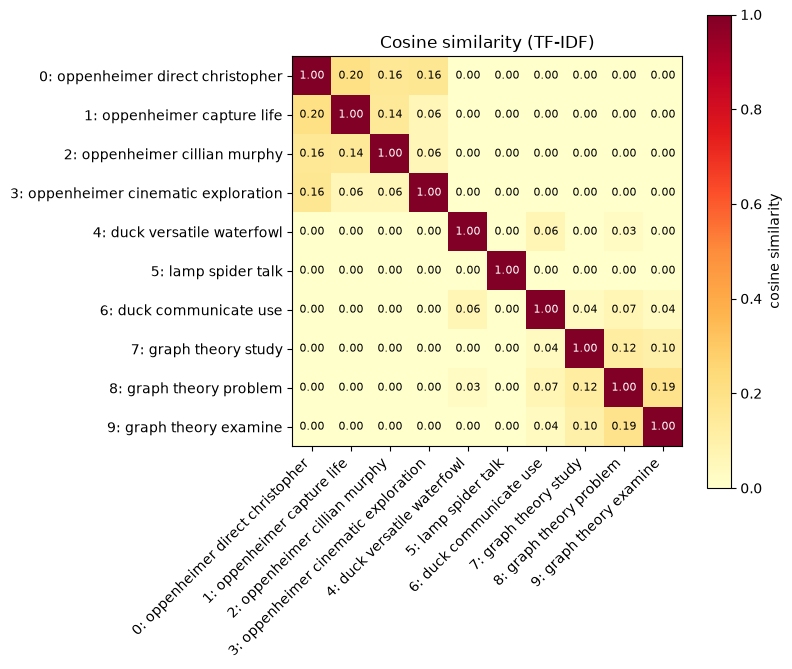

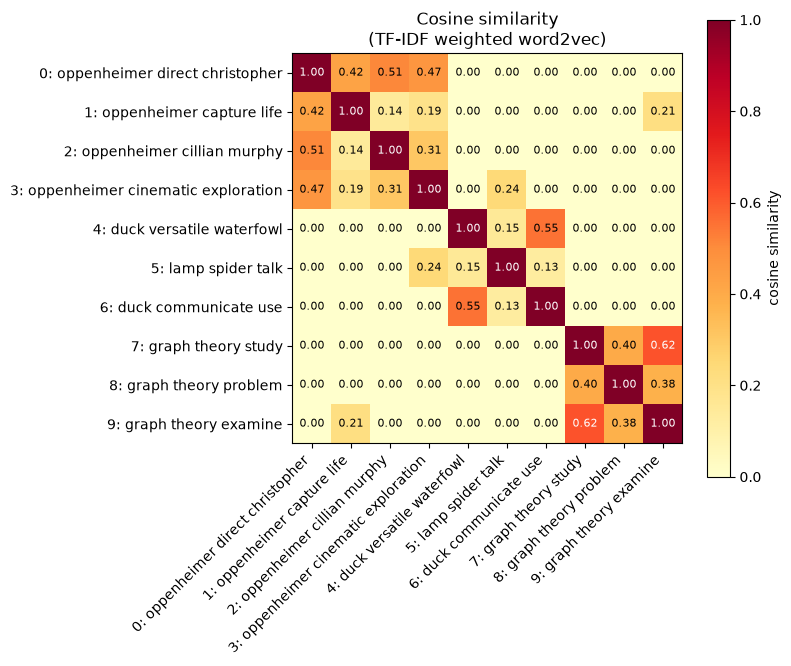

In [6]:
def visualize_data(cosine_matrix, texts_processed, title='Cosine similarity (TF-IDF)', file_name='similarity.png'):
    """
    Visualize the cosine similarity matrix from the previous task.

    Args:
        cosine_matrix (list): matrix of cosine similarity scores (values from 0.0 to 1.0 expected).
        texts_processed (list): list of texts, processed in previous task.

    Returns:
        None: None.
    """
    matrix = np.array(cosine_matrix)
    n = len(matrix)
    labels = [f'{i}: ' + ' '.join(t.split()[:3]) for i, t in enumerate(texts_processed)]

    fig, ax = plt.subplots(figsize=(max(8, n * 0.8), max(6, n * 0.7)))
    im = ax.imshow(matrix, cmap='YlOrRd', vmin=0, vmax=1)
    ax.set_xticks(range(n))
    ax.set_xticklabels(labels, rotation=45, ha='right')
    ax.set_yticks(range(n))
    ax.set_yticklabels(labels)
    for i in range(n):
        for j in range(n):
            ax.text(j, i, f'{matrix[i, j]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if matrix[i, j] > 0.6 else 'black')
    fig.colorbar(im, ax=ax, label='cosine similarity')
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(f'{IMAGES_DIR}/{file_name}', dpi=120)
    plt.show()
    return None

visualize_data(cosine_matrix, texts_processed)
visualize_data(cosine_matrix_w2v, texts_processed, 'Cosine similarity\n(TF-IDF weighted word2vec)', 'similarity_word2vec.png')

## Analyse your own text using TFIDF (or any other method)

Analyse your own text using previous methods. You may use API fetching to get text data, download texts from Kaggle or use any texts you want. Find cosine similarities and visualize them

Recommendation: use sentence_transform / openai embedding model

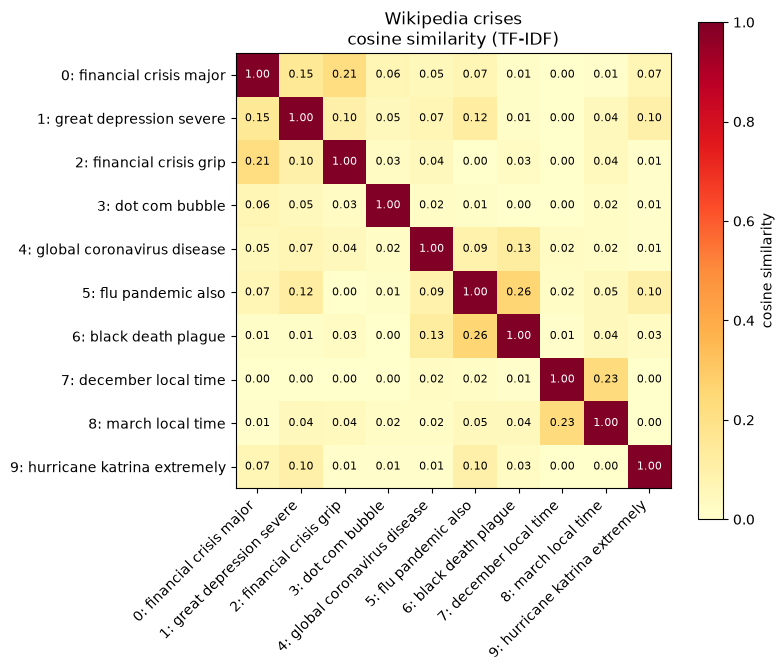

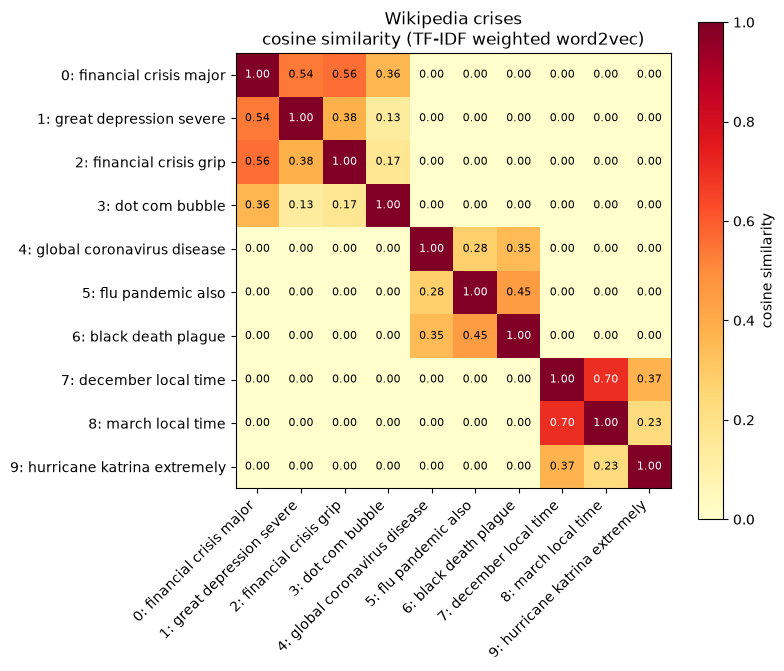

In [7]:
def get_texts():
    """
    Get the texts you want to analyse. Either API fetching, Kaggle or any other source.

    Args:
        None: None.

    Returns:
        list: list of texts.
    """
    # summaries of Wikipedia articles: economic crises, pandemics and natural disasters
    titles = [
        '2008_financial_crisis', 'Great_Depression', '1997_Asian_financial_crisis', 'Dot-com_bubble',
        'COVID-19_pandemic', 'Spanish_flu', 'Black_Death',
        '2004_Indian_Ocean_earthquake_and_tsunami', '2011_Tōhoku_earthquake_and_tsunami', 'Hurricane_Katrina',
    ]
    texts = []
    for title in titles:
        response = requests.get(f'https://en.wikipedia.org/api/rest_v1/page/summary/{title}',
                                headers={'User-Agent': 'ida-labs student assignment'}, timeout=30)
        response.raise_for_status()
        texts.append(response.json()['extract'])
    return texts

texts = get_texts()
texts_processed = process_texts(texts)
cosine_matrix = calcuate_tfidf(texts_processed)
visualize_data(cosine_matrix, texts_processed, 'Wikipedia crises\ncosine similarity (TF-IDF)', 'crises_similarity.png')
cosine_matrix_w2v = calcuate_tfidf_word2vec(texts_processed)
visualize_data(cosine_matrix_w2v, texts_processed, 'Wikipedia crises\ncosine similarity (TF-IDF weighted word2vec)',
               'crises_similarity_word2vec.png')